# Expérimentation MLflow
J'ai comparé quatre familles de modèles sur les mêmes splits train/validation et 261 features. J'ai ajusté l'imputation sur le train et sélectionné le seuil de refus sur validation en minimisant 10 × FN + FP. Le positif signifie défaut prédit/refus ; l'acceptation vaut 1 - prédiction.

J'ai choisi les paramètres LightGBM parmi six essais définis avant évaluation sur validation. Comme ce split sert aussi à choisir la famille et le seuil, ces résultats peuvent être optimistes. Je n'ai pas ouvert le test pendant l'entraînement. Les scores ne sont pas des PD calibrées, notamment avec des poids de classes équilibrés ; j'ai vérifié séparément l'équivalence des modèles rechargés depuis MLflow.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if Path("params.yaml").exists() else Path.cwd().parent
assert Path(sys.prefix).resolve() == (ROOT / "creditS").resolve()
comparison = json.loads((ROOT / "reports/model_comparison.json").read_text(encoding="utf-8"))
results = pd.DataFrame(comparison["results"]).sort_values("validation_auc", ascending=False)
print("Selection split: validation; test untouched; promotion pending fairness and SHAP.")
print("Selected candidate:", comparison["selected_model"])

Selection split: validation; test untouched; promotion pending fairness and SHAP.
Selected candidate: lightgbm


In [2]:
columns = [
    "model",
    "validation_auc",
    "validation_pr_auc",
    "validation_ks",
    "validation_gini",
    "validation_recall",
    "validation_precision",
    "threshold",
    "training_seconds",
]
print(results[columns].round(4).to_string(index=False))
print("Data SHA256:", comparison["provenance"]["training_data_sha256"])

              model  validation_auc  validation_pr_auc  validation_ks  validation_gini  validation_recall  validation_precision  threshold  training_seconds
           lightgbm          0.7487             0.2427         0.3770           0.4973             0.6146                0.1795       0.49            1.2300
            xgboost          0.7372             0.2284         0.3646           0.4745             0.6549                0.1638       0.07            2.4826
      random_forest          0.7240             0.2339         0.3294           0.4480             0.5869                0.1618       0.09            3.4736
logistic_regression          0.7210             0.1984         0.3647           0.4421             0.6096                0.1699       0.09            4.2036
Data SHA256: f25c1a50ec60b966500509aae15df822853865ffc2b9e501612846204965458d


Ranking after bounded validation search; this is not a test estimate.


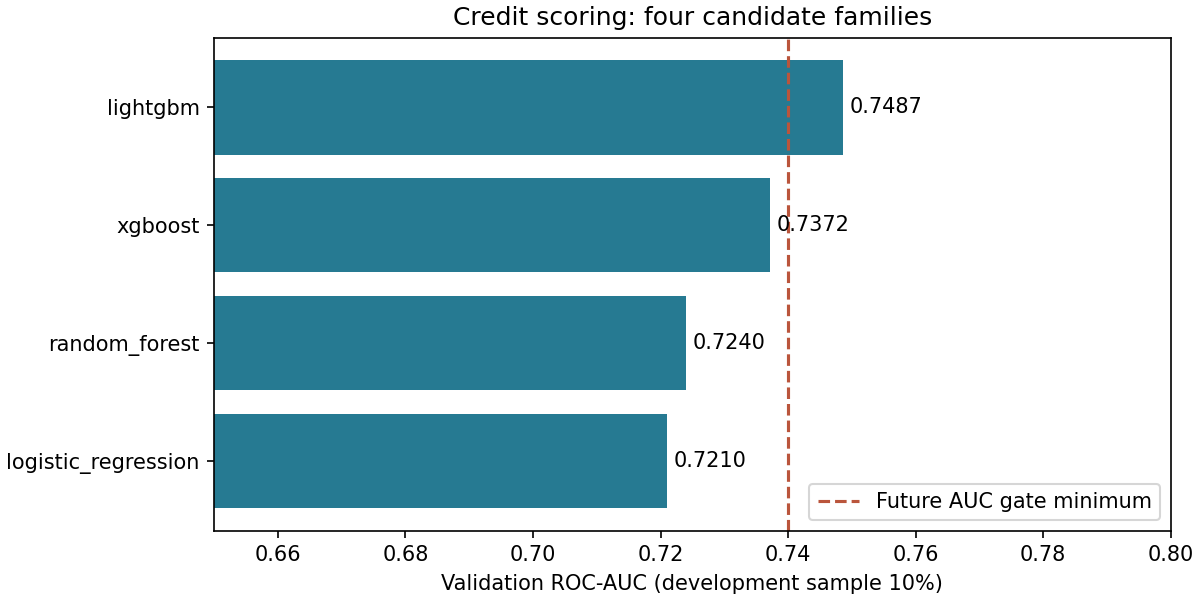

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.barh(results["model"], results["validation_auc"], color="#267a92")
ax.invert_yaxis()
ax.set_xlim(0.65, 0.80)
ax.set_xlabel("Validation ROC-AUC (development sample 10%)")
ax.set_title("Credit scoring: four candidate families")
ax.axvline(0.74, color="#ba553c", linestyle="--", label="Future AUC gate minimum")
for number, value in enumerate(results["validation_auc"]):
    ax.text(value + 0.001, number, f"{value:.4f}", va="center")
ax.legend(loc="lower right")
fig.savefig(ROOT / "reports/model_comparison.png", dpi=150)
plt.close(fig)
print("Ranking after bounded validation search; this is not a test estimate.")